# Decomposing coherent-GGI change into female and male adoption

The coherent GGI is a ratio, so its log change splits **exactly** into a female and a male term:

```
GGI_ct           = female_ct / male_ct
delta_log_GGI    = log(GGI_c,t1)    - log(GGI_c,t0)
female_component = log(female_c,t1) - log(female_c,t0)
male_component   = -[log(male_c,t1) - log(male_c,t0)]

delta_log_GGI    = female_component + male_component        (identity)
```

The point of the exercise is that a **narrowing gap is not the same thing as women gaining access**.
The gap also narrows when men lose access, or when both sexes lose access and men lose more. Those
are parity improvements without access expansion, and they are labelled as such everywhere below —
never as improved digital access.

Every table is built by `src/ggi_decomposition.py`, for **both** indicators; this notebook only
plots. **`INDICATOR` at the top of the setup cell chooses which one is displayed** — every figure
and table below is built for that indicator alone, and figures carry it in their filename, so
switching and rerunning accumulates both sets rather than overwriting one with the other.
The generated summary at the end is the one exception: it still covers both, because `doc/` is a
repo artefact and halving it would be a regression.

**`GROUPING` does the same for the two panels that aggregate countries** — the category shares and
the aggregate decomposition. It takes `continent` (the default) or the World Bank `region`; both are
built by the script on every run, so switching is a parameter, not a rerun of the script.

Primary interval **2015–2025**, with 2015–2020, 2020–2025 and all consecutive annual pairs also
computed. 2026 is excluded as a partial year (D18).

**Parity is the ceiling** (`params.level_ceiling_ctrl`). Where women's predicted adoption exceeds
men's there is no gap against women, so movement above parity must not read as a widening gap. The
cap is applied to the **female level** (`female* = min(female, male)`), which gives the same series
as capping the GGI at 1 but keeps `GGI* = female*/male` a genuine ratio — so the identity above
still holds exactly. Capping the ratio directly would break it. Rows where the cap binds are
flagged `ceiling_binding`; there the female component measures change in `min(female, male)` rather
than in female adoption alone (D25).

The typology has **five** categories (D50): the gap narrowed with women gaining access, it narrowed
because men lost access, it widened, the country was already at parity, or nothing moved. Earlier
runs split the first two by whether male adoption also rose and whether female adoption fell — eight
classes in all. Those splits subdivided a reading rather than changing it, and no legend at eight
classes stayed readable, so they are gone; the level columns are still on every row for anyone who
wants them back.

Countries **already at or above parity at both endpoints** are separated into their own category
(**4**) rather than dropped. There was no gap against women to close, so their near-zero change is a
standing state, not a negligible movement — but they stay in the denominator, because dropping them
would remove countries non-randomly by region and income. A country that *crosses into* parity
during the window is **not** in category 4: its convergence is the finding, and it keeps its
convergence category (D26).

In [1]:
import sys
from pathlib import Path

# put src/ on the path — this notebook lives in src/analysis_notebooks/
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'params.py').exists())
sys.path.insert(0, str(SRC))
import re
import warnings

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ggi_decomposition
import params
import plotting as plot

NOTEBOOK = '06_coherent_ggi_decomposition'
import utils

warnings.filterwarnings('ignore')

STYLE = params.STYLE
PALETTE = STYLE['colors']
# The ink, and the palette, come from one place — src/shared_style.py, applied by plotting.py
# (D52). Restating the hexes here is how two figures end up with two greys.
INK, MUTED, GRID = plot.INK, plot.MUTED, plot.GRID
FIGDIR = params.fig_dir(NOTEBOOK)
FIGDIR.mkdir(parents=True, exist_ok=True)

PRIMARY = '2015-2025'

# ====================================================================================================
# which indicator this run displays
# ====================================================================================================
# One indicator per run. Set it here and rerun the notebook; nothing else needs touching. The two
# indicators want different treatment rather than a shared panel — internet occupies four of the
# five categories and mobile all five, so a shared legend advertises a class that is empty for one
# of them.
INDICATOR = 'mobile'            # 'mobile' | 'internet'
assert INDICATOR in params.COHERENT_GGI['indicators'], f'unknown indicator: {INDICATOR}'

# ====================================================================================================
# how countries are grouped in the aggregate panels
# ====================================================================================================
# Two panels below aggregate countries: the category shares and the aggregate decomposition.
# `continent` is plain geography; `region` is the World Bank's, which mixes geography with income and
# administrative history ('Europe & Central Asia' is one region) — a grouping this decomposition
# makes no claim about. `ggi_decomposition.py` builds both on every run and stacks them in one table
# tagged by `grouping`, so switching is this parameter and a rerun of the notebook, not a rerun of
# the script. Figures carry it in their filename beside the indicator, so both sets accumulate.
GROUPING = 'continent'            # 'continent' | 'region'
assert GROUPING in ggi_decomposition.GROUPINGS, f'unknown grouping: {GROUPING}'
GROUP_ONE, GROUP_MANY = GROUPING, f'{GROUPING}s'
GROUP_ADJ = {'continent': 'continental', 'region': 'regional'}[GROUPING]


def latest(stem):
    matches = sorted(f for f in params.table_dir(NOTEBOOK).glob(f'ggi_decomposition_{stem}_*.csv')
                     if re.fullmatch(rf'ggi_decomposition_{stem}_\d{{8}}\.csv', f.name))
    if not matches:
        raise FileNotFoundError(f'no ggi_decomposition_{stem}_<date>.csv — run src/ggi_decomposition.py')
    return pd.read_csv(matches[-1])


codebook   = latest('codebook')
country    = latest('country_period')
exclusions = latest('exclusions')
sens       = latest('sensitivity')
identity   = latest('identity_check')
cat_global = latest('category_global')
cat_group  = latest('category_by_group')
extremes   = latest('extremes')
group_agg  = latest('group_aggregate')

CATS = codebook.sort_values('code')
CAT_LABEL = dict(zip(CATS['code'], CATS['label']))
NO_ACCESS_GAIN = {1}


def sel(df):
    """
    restrict a table to what is being displayed; pass anything else through

    Two filters, applied only where the column exists: the indicator, and — on the two tables that
    carry every categorisation stacked — the grouping. Filtering here rather than at each use is what
    keeps `GROUPING` a single switch.
    """
    if 'indicator' in df.columns:
        df = df[df['indicator'] == INDICATOR]
    if 'grouping' in df.columns:
        df = df[df['grouping'] == GROUPING]
    return df


def at(df, interval=PRIMARY):
    """the displayed indicator, at one interval"""
    d = sel(df)
    return d[d['interval'] == interval]

# Five categories on the RdYlBu ramp (D53), and the ends carry the meaning: the cool end is the
# converging/at-parity side, the warm end the side that is not converging, with `red` reserved for
# the one category where the gap actually widens. Grey is a deliberate neutral for "no material
# change", not an accidentally desaturated hue. All four coloured pairs clear the colour-vision
# floor comfortably (the tightest, cream vs red, is 29.3 dE2000 under deuteranopia). The two-level
# colour/hatch scheme the eight-category typology needed is gone (D50) — one category, one colour.
CAT_COLOUR = {
    1: params.colors['cream'],        # gap narrows, women do NOT gain access
    2: params.colors['navy'],         # gap narrows, women gain access
    3: params.colors['red'],          # gap widens
    4: params.colors['light_blue'],   # already at parity at both endpoints
    5: plot.NEUTRAL,                  # below threshold
}


def cat_style(code):
    """one category, one colour"""
    return dict(color=CAT_COLOUR[int(code)])


def legend_handles(codes):
    """
    legend entries for the categories actually present

    Built from the data rather than from the codebook, so a panel never advertises a class that is
    empty for the indicator on display — with one indicator per figure that is now the common case.
    """
    return [mpatches.Patch(facecolor=CAT_COLOUR[c], edgecolor=plot.EDGE, label=f'{CAT_LABEL[c]}')
            for c in sorted({int(c) for c in codes})]


def tidy(ax, title=None, xlabel=None, ylabel=None):
    if title:
        ax.set_title(title, fontsize=STYLE['label_fs'], color=INK, fontweight='bold', loc='left')
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=STYLE['tick_fs'], color=MUTED)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=STYLE['tick_fs'], color=MUTED)
    ax.tick_params(labelsize=STYLE['annot_fs'], colors=MUTED)
    ax.grid(axis='y', color=GRID, linewidth=0.5, alpha=0.6)
    ax.set_axisbelow(True)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    for s in ['left', 'bottom']:
        ax.spines[s].set_color(GRID)
    return ax


ceiling = latest('ceiling_report')
disc_filter = latest('discrepancy_filter')
CUT = params.COHERENT_GGI['discrepancy_threshold']
print(f'displaying: {INDICATOR.upper()}, grouped by {GROUPING.upper()}\n')
print(f"discrepancy_threshold = {params.COHERENT_GGI['discrepancy_threshold']}  "
      f"(D43: country-years where the coherent and the directly predicted GGI disagree by more\n"
      f"than this are blanked before the decomposition runs)")
display(sel(disc_filter).round(2))
print(f"level_ceiling_ctrl = {params.level_ceiling_ctrl}  (parity is the ceiling)")
# the identity is checked across every indicator and interval at once, so it is not indicator-grained
print(f"identity: max |residual| = {identity['max_abs_residual'].iloc[0]:.2e} "
      f"over {int(identity['n_rows'].iloc[0])} country-periods (tolerance {identity['tolerance'].iloc[0]:g})")
display(at(ceiling).round(2))

displaying: MOBILE, grouped by CONTINENT

discrepancy_threshold = 0.07  (D43: country-years where the coherent and the directly predicted GGI disagree by more
than this are blanked before the decomposition runs)


,indicator,cut,n,dropped,kept_pct,countries,countries_kept,countries_lost_entirely
1,mobile,0.07,2321,15,99.35,211,211,0


level_ceiling_ctrl = True  (parity is the ceiling)
identity: max |residual| = 4.44e-16 over 4752 country-periods (tolerance 1e-12)


,indicator,interval,n,n_ceiling_binding,pct_ceiling_binding,level_ceiling_ctrl
15,mobile,2015-2025,207,126,60.87,True


## The discrepancy filter, and what it costs this notebook

Everything below runs on the filtered series (D43): a country-year whose coherent GGI disagrees
with the directly predicted one by more than **0.07** is blanked for that indicator before the
decomposition starts. The levels are what the coherent GGI is built from, so a disagreement about
the ratio is a disagreement about the levels — decomposing it would attribute a construction
artefact to female or male adoption.

**The cost compounds, and it is larger here than in `05`.** A decomposition needs a level at *both*
endpoints of an interval, so losing either 2015 or 2025 loses the country from the whole interval.
The filter removes 21% of internet country-years, but the internet 2015–2025 decomposition falls
from **201 countries to 127**. Mobile is barely touched: 211 to 207, losing only Iraq, Niger, Niue
and Chad.

Read the internet panels below as *the countries where the two constructions of the GGI agree*, not
as a global picture. That is a defensible sample — it is the sample whose levels the appendix is
willing to stand behind — but it is a different one from the pre-filter vintage, and group shares
shift with composition as well as with adoption.


## Codebook

The five categories are mutually exclusive and exhaustive by construction: `delta` is either below
the threshold in absolute value, negative, or positive, and the convergence branch splits on one
further test. `f` and `m` are the log changes in female and male adoption; `delta = f - m` is the
log change in the GGI. The threshold is **τ = 0.013 log points** (about a 1.3% relative change over the interval).

Category **1** is the one to watch: the gap narrowed while women's own access was flat or falling,
so it can only have narrowed because men lost more. That is a parity improvement, not an access
improvement, and it carries `parity_improved_without_access_gain = True`.

**τ was raised from 0.01 to 0.013 (D55).** At 0.01 the only thing separating South Korea's mobile series from flat was a `delta` of **−0.0124** over ten years — about 0.12% a year — and it was reported as **divergence**, a widening gender gap. That is a threshold artefact, not a finding. 0.013 clears it and nothing else near it: the two mobile divergences that remain, Turkmenistan (−0.042) and Kiribati (−0.066), sit three to five times further out. On the 2015–2025 interval the change moves ten countries in total — South Korea from 3 to 5, and nine marginal category-2 countries into 5.


In [2]:
codebook[['code', 'label', 'parity', 'female_access', 'rule', 'reading']]

,code,label,parity,female_access,rule,reading
0,1,Converging - male decreasing,improving,stable or contracting,delta > tau; f <= tau,The gap narrowed without women gaining access:...
1,2,Converging - female increasing,improving,expanding,delta > tau; f > tau,The gap narrowed and women gained access: fema...
2,3,Divergence,worsening,varies,delta < -tau,The gap widened: male adoption rose proportion...
3,4,At or above parity throughout,at parity,varies,female >= male at BOTH endpoints (requires lev...,Women's predicted adoption met or exceeded men...
4,5,Negligible change,stable,varies,|delta| <= tau,Parity change below the 0.013 log-point thresh...


## Exclusions and the epsilon sensitivity

A country is dropped from an interval when either level is **missing or zero** at either endpoint.
Since D43 the two reasons are very unequal: almost every exclusion is a country-year the discrepancy
filter blanked, and the `log(0)` case survives in exactly one row. The table separates them.

`log(0)` does not exist, so no constant is added to the primary results. The sensitivity below shows
what an `epsilon = 0.001` substitution would do.

In [3]:
display(sel(exclusions)[exclusions['interval'].isin(['2015-2025', '2015-2020', '2020-2025'])]
        [['indicator', 'interval', 'n_countries_available', 'n_included', 'n_excluded',
          'n_excluded_zero_female', 'n_excluded_zero_male', 'excluded_iso3']])
sel(sens)[['indicator', 'interval', 'epsilon', 'n_primary', 'n_with_epsilon',
           'n_recovered', 'max_abs_change_on_shared']]

,indicator,interval,n_countries_available,n_included,n_excluded,n_excluded_zero_female,n_excluded_zero_male,excluded_iso3
13,mobile,2015-2025,211,207,4,0,0,"IRQ,NER,NIU,TCD"
14,mobile,2015-2020,211,207,4,0,0,"IRQ,NER,NIU,TCD"
15,mobile,2020-2025,211,211,0,0,0,NaN


,indicator,interval,epsilon,n_primary,n_with_epsilon,n_recovered,max_abs_change_on_shared
3,mobile,2015-2025,0.001,207,211,4,0.0
4,mobile,2015-2020,0.001,207,211,4,0.0
5,mobile,2020-2025,0.001,211,211,0,0.0


The substitution changes **no** existing estimate (`max_abs_change_on_shared = 0`); it only
manufactures a log change for countries whose level is exactly zero. Those values would be an
artefact of the constant rather than an estimate, so the primary results keep the exclusions.

**The excluded set is not random, and since D43 it leaves by a different door.** Before the
discrepancy filter, the internet exclusions were the countries whose predicted female level sits on
the level model's zero floor (D19). Those countries are still absent — but nine of the ten are now
blanked by the filter *before* `decompose` sees them, so they are counted as missing rather than as
zeros, and only Niger (both levels 0 in 2015) still exits through `log(0)`.

Either way the substantive point is unchanged: the countries that drop out are among the most
gender-unequal in the sample, so the reported distribution understates the tail. Internet results
for 2015–2025 describe the **127** countries where a log change exists, not the full 211.

## Category shares, global and by group

One figure, four panels. The columns are the two weightings; the rows are the two levels of
aggregation. Shares are reported unweighted and weighted by each country's **total population aged
15-49** — both sexes on one denominator, the DHS/MICS interview universe the ground truth is drawn
from (D50). A sex-specific weight would make the female and male halves of the same identity refer
to different populations.

Keeping all four on one canvas is the point: the global strip is the grouped panel's weighted
average, so reading them side by side shows which groups the global share is actually made of, and
the two columns show how much of the global picture is a population-size effect rather than a
country-count one.

**`GROUPING` at the top of the setup cell chooses the grouping** — `continent` (the default) or the
World Bank `region`. The figure carries it in its filename, so switching and rerunning accumulates
both rather than overwriting one with the other.

**One category, one colour.** At five classes hue alone carries the whole typology; the warm end
carries the two categories that are not convergence-with-access — pale `cream` where the gap
narrowed *without* women gaining access, and `red` where it widened.


,category,category_label,n_countries,share_unweighted,share_pop_weighted
75,1,Converging - male decreasing,1,0.0048,0.0017
76,2,Converging - female increasing,104,0.5024,0.6665
77,3,Divergence,2,0.0097,0.0012
78,4,At or above parity throughout,72,0.3478,0.2283
79,5,Negligible change,28,0.1353,0.1022


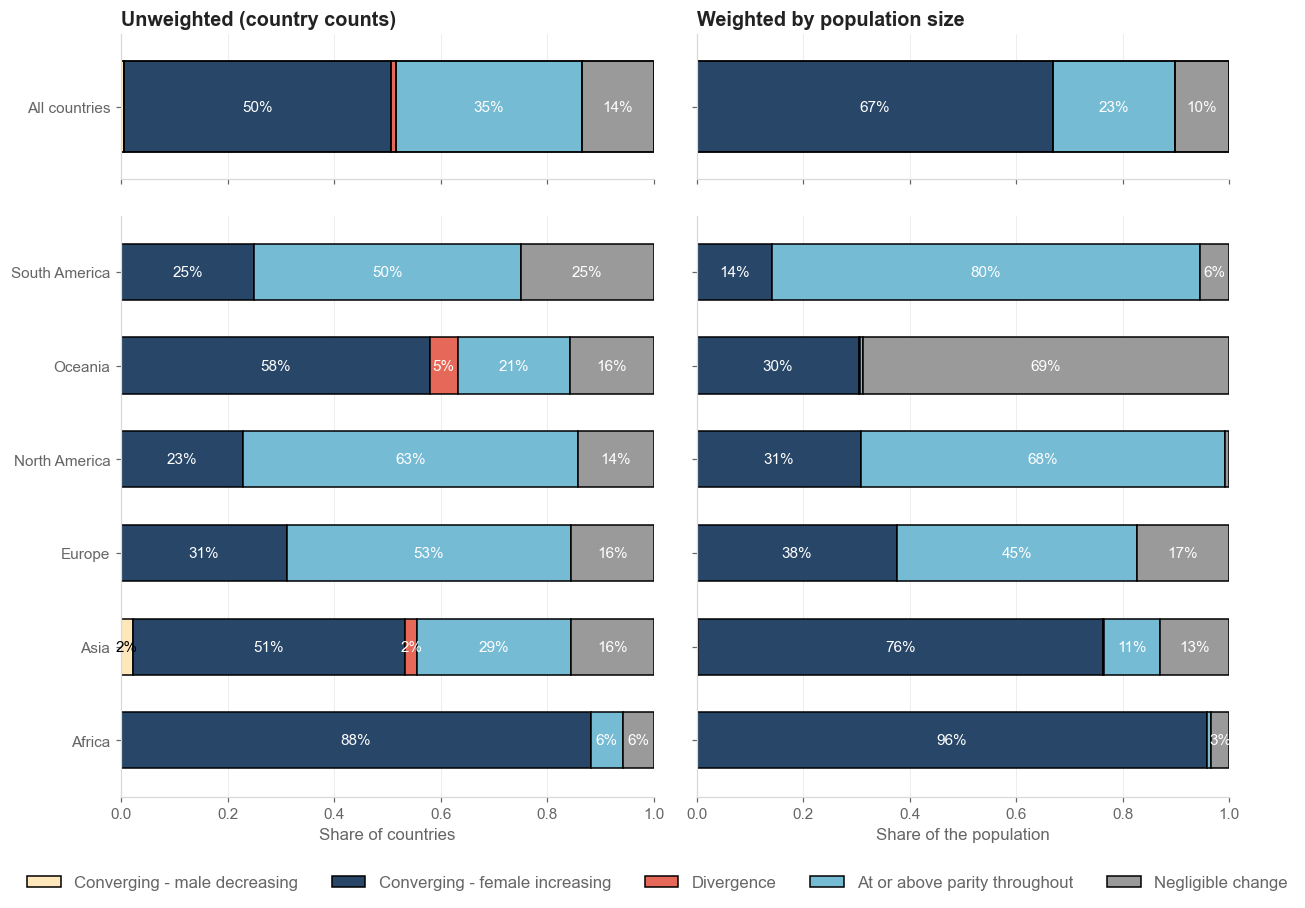

In [4]:
glob_block = at(cat_global)
grp_block = at(cat_group)
groups = sorted(grp_block['group'].dropna().unique())

WEIGHTINGS = ['share_unweighted', 'share_pop_weighted']
COL_TITLE = {'share_unweighted': 'Unweighted (country counts)', 'share_pop_weighted': 'Weighted by population size'}

# The global strip is one bar and the grouped panel is six or seven, so equal row heights would give
# the strip several times the ink per bar. height_ratios puts them on the same bar height instead.
fig, axes = plt.subplots(2, 2, figsize=plot.figsize('tall'), sharex=True,
                         gridspec_kw={'height_ratios': [1, 4], 'hspace': 0.10, 'wspace': 0.08})

for col, weighting in enumerate(WEIGHTINGS):
    # ---- top row: the global strip ---------------------------------------------------------------
    ax = axes[0, col]
    left = 0.0
    for _, row in glob_block.sort_values('category').iterrows():
        width = row[weighting]
        ax.barh(0, row[weighting], left=left, height=0.5,
                edgecolor=plot.EDGE, linewidth=1.2, **cat_style(row['category'])),
        ax.text(
    left + width / 2,
    0,
    f"{width:.0%}" if width > 0.02 else '',
    ha='center',
    va='center',
    fontsize=STYLE['annot_fs'],
    color="white")
        left += row[weighting]
    ax.set_yticks([0])
    # the row label belongs to the row, not to each panel — only the left column carries it
    ax.set_yticklabels(['All countries'] if col == 0 else [])
    ax.set_ylim(-0.4, 0.4)
    # add annotation to the top row, not the bottom row, so it is not repeated for each panel
    
    tidy(ax, title=COL_TITLE[weighting])

    # ---- bottom row: the same shares, by group ----------------------------------------------------
    ax = axes[1, col]
    left = dict.fromkeys(groups, 0.0)
    for _, row in grp_block.sort_values(['group', 'category']).iterrows():
        group = row['group']
        width= row[weighting]
        ax.barh(groups.index(group), row[weighting], left=left[group], height=0.6,
                edgecolor=plot.EDGE, linewidth=1.0, **cat_style(row['category']))
        
        ax.text(
            left[group] + width / 2,
            groups.index(group),
            f"{width:.0%}" if width > 0.02 else '',
            ha='center',
            va='center',
            fontsize=STYLE['annot_fs'],
            color="white" if row['category']!=1 else "black")
        left[group] += row[weighting]
    ax.set_yticks(range(len(groups)))
    ax.set_yticklabels(groups if col == 0 else [])
    ax.set_ylim(-0.6, len(groups) - 0.4)
    tidy(ax, xlabel='Share of countries' if weighting == 'share_unweighted'
                    else 'Share of the population')

for ax in axes.ravel():
    ax.set_xlim(0, 1)
    ax.grid(axis='y', visible=False)
    ax.grid(axis='x', color=GRID, linewidth=0.5, alpha=0.6)

# the legend covers every panel, so it is built from both blocks rather than from either one
present = pd.concat([glob_block.loc[glob_block['n_countries'] > 0, 'category'],
                     grp_block.loc[grp_block['n_countries'] > 0, 'category']])
fig.legend(handles=legend_handles(present), loc='lower center', ncol=5, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, 0),)
           #title='Decomposition category', title_fontsize=STYLE['tick_fs'])
#fig.suptitle(f'{INDICATOR.capitalize()} — decomposition categories, global and by {GROUP_ONE}, {PRIMARY}',
#             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0.09, 1, 0.95])
plot.save_fig(fig, FIGDIR / f'category_shares_{INDICATOR}_{GROUPING}.png')
display(glob_block[['category', 'category_label', 'n_countries',
                    'share_unweighted', 'share_pop_weighted']].round(4))

In [5]:
width

0.0555763609668065

In [6]:
grp_block

,indicator,interval,grouping,group,category,category_label,n_countries,share_unweighted,share_pop_weighted,parity_improved_without_access_gain
450,mobile,2015-2025,continent,Africa,1,Converging - male decreasing,0,0.000000,0.000000,True
451,mobile,2015-2025,continent,Africa,2,Converging - female increasing,45,0.882353,0.957955,False
452,mobile,2015-2025,continent,Africa,3,Divergence,0,0.000000,0.000000,False
453,mobile,2015-2025,continent,Africa,4,At or above parity throughout,3,0.058824,0.007268,False
454,mobile,2015-2025,continent,Africa,5,Negligible change,3,0.058824,0.034777,False
455,mobile,2015-2025,continent,Asia,1,Converging - male decreasing,1,0.022222,0.003237,True
456,mobile,2015-2025,continent,Asia,2,Converging - female increasing,23,0.511111,0.758984,False
457,mobile,2015-2025,continent,Asia,3,Divergence,1,0.022222,0.002269,False
458,mobile,2015-2025,continent,Asia,4,At or above parity throughout,13,0.288889,0.106013,False
459,mobile,2015-2025,continent,Asia,5,Negligible change,7,0.155556,0.129497,False


### Both indicators and both weightings on one canvas

The figure above shows one indicator at a time, as the rest of the notebook does. This is the global
strip for **both** indicators and **both** weightings in one frame — four bars, the same five
categories, the same colours, one legend.

**This figure ignores `INDICATOR`**, like `female_vs_male_growth_pair`, and it ignores `GROUPING`
too: these are the global shares, which are not grouped. It is written as
`category_shares_pair.{pdf,png}`, so it does not collide with the per-indicator
`category_shares_<indicator>_<grouping>` above.

What the pair is for: the two indicators divide the same typology very differently, and that
contrast is the finding. Internet puts two thirds of countries in category 2 and has **no**
divergence at all; mobile splits between category 2 and a much larger category 4, because 72 mobile
countries were already at parity in 2015 and had no gap to close. Reading the two weightings side by
side separates a country-count effect from a population one — mobile's category 2 rises from 50% of
countries to 67% of the population, which is the large South Asian and Sub-Saharan African countries
carrying more weight than their count.

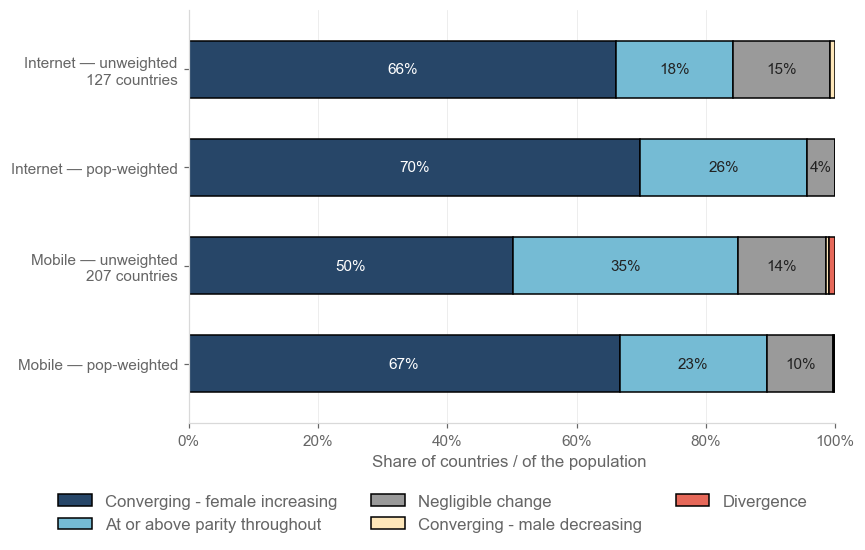

  wrote outputs/fig/06_coherent_ggi_decomposition/category_shares_pair.pdf
  wrote outputs/fig/06_coherent_ggi_decomposition/category_shares_pair.png


,indicator,category,category_label,n_countries,share_unweighted,share_pop_weighted
0,internet,1,Converging - male decreasing,1,0.0079,0.0000
1,internet,2,Converging - female increasing,84,0.6614,0.6985
2,internet,3,Divergence,0,0.0000,0.0000
3,internet,4,At or above parity throughout,23,0.1811,0.2585
4,internet,5,Negligible change,19,0.1496,0.0430
5,mobile,1,Converging - male decreasing,1,0.0048,0.0017
6,mobile,2,Converging - female increasing,104,0.5024,0.6665
7,mobile,3,Divergence,2,0.0097,0.0012
8,mobile,4,At or above parity throughout,72,0.3478,0.2283
9,mobile,5,Negligible change,28,0.1353,0.1022


In [20]:
# Both indicators, both weightings, one canvas — the pair version of the global strip above.
# Reads `cat_global` directly rather than through `sel`/`at`: the whole point is to show the
# indicator that is *not* on display (the `female_vs_male_growth_pair` precedent).
PAIR = params.COHERENT_GGI['indicators']          # internet, mobile — params' own order

# Stacking order, largest-to-smallest by typical share, with the two counter-example categories
# last so they stay legible as slivers at the right-hand end rather than being buried mid-bar.
STACK = [2, 4, 5, 1, 3]

# Text on a segment has to clear the segment it sits on, and the five category colours are not all
# dark: navy and red take white, the ramp's light steps and the neutral take the project ink.
ON_DARK = {2, 3}
MIN_LABEL_WIDTH = 0.04                            # narrower than this and the label will not fit

rows = [(ind, w) for ind in PAIR
        for w in ('share_unweighted', 'share_pop_weighted')]
WEIGHT_LABEL = {'share_unweighted': 'unweighted', 'share_pop_weighted': 'pop-weighted'}

block = cat_global[cat_global['interval'] == PRIMARY].set_index(['indicator', 'category'])
n_countries = {ind: int(block.loc[ind, 'n_countries'].sum()) for ind in PAIR}

fig, ax = plt.subplots(figsize=(8,5))

for y, (indicator, weighting) in enumerate(rows):
    left = 0.0
    for code_ in STACK:
        if (indicator, code_) not in block.index:
            continue
        width = float(block.loc[(indicator, code_), weighting])
        if width <= 0:
            continue
        ax.barh(y, width, left=left, height=0.58, edgecolor=plot.EDGE, linewidth=1.0,
                **cat_style(code_))
        if width >= MIN_LABEL_WIDTH:
            ax.text(left + width / 2, y, f'{width:.0%}', ha='center', va='center',
                    fontsize=STYLE['annot_fs'],
                    color='white' if code_ in ON_DARK else INK)
        left += width

# Two lines per tick: what the bar is, and what its denominator is. The denominator is the thing a
# reader has to know to compare the two weightings at all, so it travels with the label rather than
# sitting in the caption.
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{ind.capitalize()} — {WEIGHT_LABEL[w]}\n"
                    f"{n_countries[ind]} countries" if w == 'share_unweighted'
                    else f"{ind.capitalize()} — {WEIGHT_LABEL[w]}"
                    for ind, w in rows],
                   fontsize=STYLE['annot_fs'])
ax.invert_yaxis()                                  # internet on top, reading order
ax.set_xlim(0, 1)
ax.set_ylim(len(rows) - 0.4, -0.6)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
tidy(ax, xlabel='Share of countries / of the population ')
ax.grid(axis='y', visible=False)
ax.grid(axis='x', color=GRID, linewidth=0.5, alpha=0.6)

# The legend covers both indicators, so it is built from both blocks — internet occupies four of the
# five categories and mobile all five, so taking it from either alone would drop a class.
# Ordered by STACK, not by category code: the legend then reads left-to-right in the same order the
# segments run, which is the only order a reader can actually follow along a stacked bar.
present = set(cat_global.loc[(cat_global['interval'] == PRIMARY)
                             & (cat_global['n_countries'] > 0), 'category'].astype(int))
handles = [h for code_ in STACK if code_ in present for h in legend_handles([code_])]
plot.legend(fig, handles, ncol=3, y=-0.03)

fig.tight_layout(rect=[0, 0.08, 1, 0.98])
paths = plot.save(fig, NOTEBOOK, 'category_shares_pair')
plt.show()

for p in paths:
    print(f'  wrote {p.relative_to(params.ROOT)}')
display(block.reset_index()[['indicator', 'category', 'category_label', 'n_countries',
                             'share_unweighted', 'share_pop_weighted']].round(4))

## Female against male growth

Each point is a country over 2015–2025. The diagonal `y = x` is the **convergence/divergence
boundary**: above it female adoption grew proportionally faster and the gap narrowed; below it the
gap widened. The axes are log changes, so the vertical distance from the diagonal *is*
`delta_log_GGI`.

The quadrants matter for interpretation. Only the upper-right quadrant above the diagonal is both a
parity improvement and an access expansion. Points left of the vertical zero line had female
adoption fall; points below the horizontal zero line had male adoption fall.

The **five countries with the largest female log change** are ringed and carry their value. They answer the access question the diagonal cannot: the diagonal only says whether the gap narrowed, and a country can sit far above it on a female change of almost nothing.


  named 8 of 207 points — every case in categories [1, 3], plus the 5 largest female log changes (ringed, with their value)


,country,category,female_component,male_log_change,delta_log_ggi
2050,Burkina Faso,2,0.5915,0.3357,0.2558
2049,Benin,2,0.5695,0.2702,0.2993
2168,Malawi,2,0.5481,0.2837,0.2643
2204,South Sudan,2,0.5337,0.2588,0.2749
2180,Pakistan,2,0.5275,0.1851,0.3424


[PosixPath('/Users/valler/Python/RA/Gender_Inequality/dgg_national/outputs/fig/06_coherent_ggi_decomposition/female_vs_male_growth_mobile.pdf'),
 PosixPath('/Users/valler/Python/RA/Gender_Inequality/dgg_national/outputs/fig/06_coherent_ggi_decomposition/female_vs_male_growth_mobile.png')]

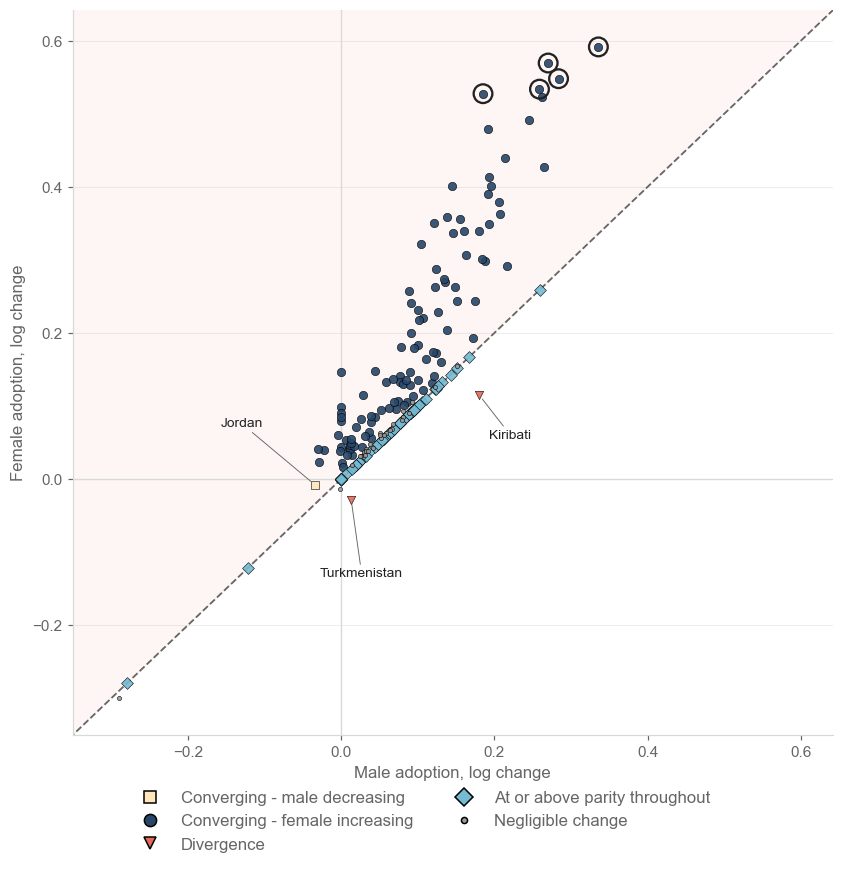

In [8]:
MARKER = {1: 's', 2: 'o', 3: 'v', 4: 'D', 5: '.'}
TOP_FEMALE = 5                    # countries with the largest female log change, highlighted and valued

fig, ax = plt.subplots(figsize=plot.figsize('square'))
block = at(country)

# male_component is -(log change in male adoption); plot the raw male log change
x, y = block['male_log_change'], block['female_component']
# One limit for both axes, so the diagonal is a true 45 degrees and the vertical distance from it
# reads as delta_log_GGI. The top is reopened after the labels are placed — see the end of the cell.
lim = [min(x.min(), y.min()) - 0.05, max(x.max(), y.max()) + 0.05]
# the diagonal and its shading are drawn well past the limits so that reopening the top does not
# leave them ending in mid-air
span = [lim[0] - 1, lim[1] + 1]

ax.axhline(0, color=GRID, linewidth=0.9)
ax.axvline(0, color=GRID, linewidth=0.9)
ax.plot(span, span, ls='--', color=MUTED, linewidth=1.2, zorder=2)
ax.fill_between(span, span, [span[1]] * 2, color=PALETTE[0], alpha=0.06, zorder=1)

for code_ in sorted(block['category'].dropna().unique()):
    pts = block[block['category'] == code_]
    ax.scatter(pts['male_log_change'], pts['female_component'], s=30, alpha=0.9,
               color=CAT_COLOUR[int(code_)], edgecolor=plot.EDGE, linewidth=0.4, zorder=3,
               marker=MARKER[int(code_)])

# ---- name the countries that carry the small categories, and the largest female gains ------------
# 3 is divergence and 1 is convergence through male decline — the two counter-examples a reader goes
# looking for, and both are small enough to name every case. Naming all of category 2 would be
# unreadable, so the five largest female log changes stand for it: they are the countries where
# women's own adoption grew most, which is the access question rather than the parity one, and they
# carry their value because the whole figure is in log points and the eye cannot read one off an axis.
# Internet has no divergence case at all over 2015-2025, which is itself the finding.
NAME_ALL = [1, 3]                 # every case in these categories

top = block.nlargest(TOP_FEMALE, 'female_component')
labelled = pd.concat([block[block['category'].isin(NAME_ALL)], top]).drop_duplicates('gid_0')
labelled = labelled.assign(highlight=labelled['gid_0'].isin(top['gid_0']))
# the value goes only on the highlighted five; elsewhere it would be five labels of noise
labelled['text'] = np.where(labelled['highlight'],
                            labelled['country'] + '\n' + labelled['female_component'].map('{:+.2f}'.format),
                            labelled['country'])

# a ring rather than a bigger marker, so the category colour and glyph underneath stay readable
ax.scatter(top['male_log_change'], top['female_component'], s=150, facecolor='none',
           edgecolor=INK, linewidth=1.5, zorder=4)

# Labels go away from the diagonal, so a leader line never crosses it: up-left for the points above
# it, down-right for those below. Within each side they are stacked in the plot's own y-order, which
# keeps the leader lines from crossing each other and separates points only a few thousandths apart
# (Algeria and Oman differ by 0.009 — about ten pixels). The step allows for the two-line labels.
def place(rows, dx, start, step, ascending):
    """stack one group of labels in the plot's own y-order, and return the annotations"""
    out = []
    for rank, (_, row) in enumerate(rows.sort_values('female_component', ascending=ascending)
                                        .iterrows()):
        out.append(ax.annotate(
            row['text'], xy=(row['male_log_change'], row['female_component']),
            xytext=(dx, start + step * rank), textcoords='offset points',
            ha='right' , va='center',
            fontsize=STYLE['small_fs'], color=INK, zorder=5,
            fontweight='bold' if row['highlight'] else 'normal',
            arrowprops=dict(arrowstyle='-', linewidth=0.6, color=MUTED, shrinkA=0, shrinkB=3)))
    return out

rest = labelled[~labelled['highlight']]
above = rest['female_component'] > rest['male_log_change']
anns = (
    # The ringed points sit together in the top-right corner, and a ladder climbing above them
    # leaves the axes. They go left and *down* into the empty upper-left instead — the region above
    # the diagonal and left of the cloud is the one part of a convergence plot that is always empty.
    place(labelled[labelled['highlight']], dx=-50, start=20, step=-20, ascending=False)
    # everything else keeps the away-from-the-diagonal rule, so no leader line crosses it
    + place(rest[above], dx=100, start=20, step=5, ascending=True) if INDICATOR == 'internet' else place(rest[above], dx=-34, start=40, step=22, ascending=True)
    + place(rest[~above], dx=34, start=-26, step=-22, ascending=False))

print(f'  named {len(labelled)} of {len(block)} points — every case in categories '
      f'{NAME_ALL}, plus the {TOP_FEMALE} largest female log changes (ringed, with their value)')
display(top[['country', 'category', 'female_component', 'male_log_change', 'delta_log_ggi']].round(4))

#ax.text(0.02, 0.97, 'above the diagonal:\ngap narrows', transform=ax.transAxes,
#        va='top', ha='left', fontsize=STYLE['annot_fs'], color=MUTED)
#ax.text(0.97, 0.03, 'below the diagonal:\ngap widens', transform=ax.transAxes,
#        va='bottom', ha='right', fontsize=STYLE['annot_fs'], color=MUTED)
tidy(ax, xlabel='Male adoption, log change', ylabel='Female adoption, log change')
ax.set_xlim(lim)
ax.set_ylim(lim)

# The label ladder is a pixel offset from its point, so how far it reaches depends on how many
# points are above the diagonal — a number that changes with the indicator and the interval. Rather
# than hard-code headroom that is wrong for one of them, measure where the labels actually ended up
# and reopen the top until they fit. Both axes move together so the diagonal stays at 45 degrees;
# it converges in two passes because moving the top also moves the anchors.
for _ in range(4):
    fig.canvas.draw()
    to_data = ax.transData.inverted().transform
    reach = max(to_data((0, a.get_window_extent().y1))[1] for a in anns) + 0.03
    if reach <= ax.get_ylim()[1] + 1e-9:
        break
    ax.set_xlim(lim[0], reach)
    ax.set_ylim(lim[0], reach)

present = sorted(block['category'].dropna().unique())
marker_handles = [plt.Line2D([], [], linestyle='None', markersize=8, marker=MARKER[int(c)],
                             markerfacecolor=CAT_COLOUR[int(c)], markeredgecolor=plot.EDGE,
                             label=f'{CAT_LABEL[c]}') for c in present]
#marker_handles.append(plt.Line2D([], [], linestyle='None', markersize=11, marker='o',
#                                 markerfacecolor='none', markeredgecolor=INK, markeredgewidth=1.5,
#                                 label=f'{TOP_FEMALE} largest female log changes'))
fig.legend(handles=marker_handles,
           loc='lower center', ncol=2, frameon=False, fontsize=STYLE['tick_fs'],
           labelcolor=MUTED, bbox_to_anchor=(0.5, -0.08),
           )# title='Decomposition category', title_fontsize=STYLE['tick_fs']
#fig.suptitle(f'{INDICATOR.capitalize()} — female against male adoption growth, {PRIMARY}',
#             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.94])
plot.save_fig(fig, FIGDIR / f'female_vs_male_growth_{INDICATOR}.png')

### Both indicators on one canvas

The panel above shows one indicator at a time, as the rest of the notebook does. This is the pair in
one frame, for the contrast: the same categories, the same colours and glyphs, the same rings on the
five largest female log changes, one legend.

**Each panel keeps its own limits.** Mobile's log changes are roughly a third the size of internet's,
so a shared scale would flatten mobile into the origin. What carries across the pair is the diagonal
— it is the convergence/divergence boundary in both panels — not the axis numbers, and the two
panels' distances from it are not comparable in magnitude. This figure is the one thing here that
ignores `INDICATOR`; it is written as `female_vs_male_growth_pair.{pdf,png}`.


In [9]:
plot.figsize('single')

(8.5, 5.5)

  internet: 127 countries, 4 named — every case in categories [1, 3], plus the 3 largest female log changes (ringed, with their value)
  mobile: 207 countries, 6 named — every case in categories [1, 3], plus the 3 largest female log changes (ringed, with their value)


[PosixPath('/Users/valler/Python/RA/Gender_Inequality/dgg_national/outputs/fig/06_coherent_ggi_decomposition/female_vs_male_growth_pair.pdf'),
 PosixPath('/Users/valler/Python/RA/Gender_Inequality/dgg_national/outputs/fig/06_coherent_ggi_decomposition/female_vs_male_growth_pair.png')]

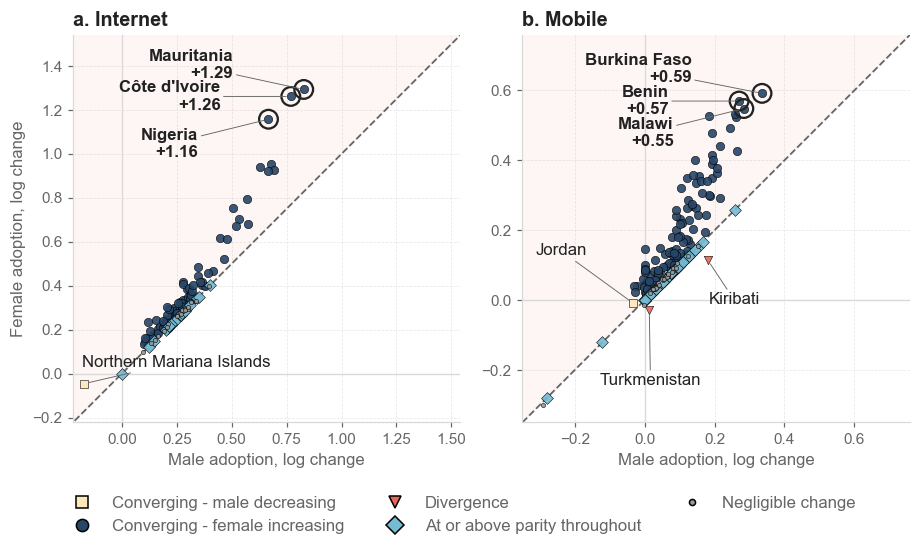

In [10]:
PAIR = ['internet', 'mobile']

# Label ladders in offset points, per panel: (dx, start, step). The rule is the one the single
# figure uses — labels go away from the diagonal, so no leader line crosses it, and each group is
# stacked in the plot's own y-order so the lines do not cross each other. The reach differs by panel
# because the two clouds have different shapes: internet's sits tight in the top-right corner,
# mobile's is looser and carries the two divergences below the diagonal.
LADDER = {
    'internet': dict(highlight=(-46, 16, -16), above=(122, 14, 5), below=(30, -24, -20)),
    'mobile':   dict(highlight=(-46, 16, -16), above=(-30, 34, 18), below=(34, -26, -20)),
}

TOP_FEMALE = 3                # countries
def growth_panel(ax, indicator, ladder):
    """
    one indicator's female-against-male panel

    The marks, the ring, the labelling rule and the tidy() treatment are the single-indicator
    figure's; only the axes are new. It reads `country` directly rather than through `sel`/`at`,
    because the whole point of this figure is to show the indicator that is *not* on display.
    """
    block = country[(country['indicator'] == indicator) & (country['interval'] == PRIMARY)]
    x, y = block['male_log_change'], block['female_component']
    # one limit for both axes, so the diagonal is a true 45 degrees and the vertical distance from
    # it reads as delta_log_GGI; the diagonal is drawn past the limits so reopening the top later
    # does not leave it ending in mid-air
    lim = [min(x.min(), y.min()) - 0.05, max(x.max(), y.max()) + 0.05]
    span = [lim[0] - 1, lim[1] + 1]

    ax.axhline(0, color=GRID, linewidth=0.9)
    ax.axvline(0, color=GRID, linewidth=0.9)
    ax.plot(span, span, ls='--', color=MUTED, linewidth=1.2, zorder=2)
    ax.fill_between(span, span, [span[1]] * 2, color=PALETTE[0], alpha=0.06, zorder=1)

    for code_ in sorted(block['category'].dropna().unique()):
        pts = block[block['category'] == code_]
        ax.scatter(pts['male_log_change'], pts['female_component'], s=30, alpha=0.9,
                   color=CAT_COLOUR[int(code_)], edgecolor=plot.EDGE, linewidth=0.4, zorder=3,
                   marker=MARKER[int(code_)])

    top = block.nlargest(TOP_FEMALE, 'female_component')
    labelled = pd.concat([block[block['category'].isin(NAME_ALL)], top]).drop_duplicates('gid_0')
    labelled = labelled.assign(highlight=labelled['gid_0'].isin(top['gid_0']))
    labelled['text'] = np.where(labelled['highlight'],
                                labelled['country'] + '\n' + labelled['female_component'].map('{:+.2f}'.format),
                                labelled['country'])
    # a ring rather than a bigger marker, so the category colour and glyph underneath stay readable
    ax.scatter(top['male_log_change'], top['female_component'], s=150, facecolor='none',
               edgecolor=INK, linewidth=1.5, zorder=4)

    def place(rows, dx, start, step, ascending):
        """stack one group of labels in the plot's own y-order, and return the annotations"""
        out = []
        for rank, (_, row) in enumerate(rows.sort_values('female_component', ascending=ascending)
                                            .iterrows()):
            out.append(ax.annotate(
                row['text'], xy=(row['male_log_change'], row['female_component']),
                xytext=(dx, start + step * rank), textcoords='offset points',
                ha='right', va='center',
                fontsize=STYLE['tick_fs'], color=INK, zorder=5,
                fontweight='bold' if row['highlight'] else 'normal',
                arrowprops=dict(arrowstyle='-', linewidth=0.6, color=MUTED, shrinkA=0, shrinkB=3)))
        return out

    rest = labelled[~labelled['highlight']]
    above = rest['female_component'] > rest['male_log_change']
    anns = (place(labelled[labelled['highlight']], *ladder['highlight'], ascending=False)
            + place(rest[above], *ladder['above'], ascending=True)
            + place(rest[~above], *ladder['below'], ascending=False))

    tidy(ax, title=f"{'a' if indicator =='internet' else 'b'}. {indicator.capitalize()}", xlabel='Male adoption, log change')
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    # the panels are no longer square canvases of their own, so the aspect has to be pinned or the
    # diagonal stops being 45 degrees and the vertical distance from it stops reading as the GGI change
    ax.set_aspect('equal', adjustable='box')
    return dict(block=block, lim=lim, anns=anns)


fig, axes = plt.subplots(1, len(PAIR), figsize=plot.figsize('single'))
panels = [growth_panel(ax, ind, LADDER[ind]) for ax, ind in zip(axes, PAIR)]
# the axis label belongs to the row, not to each panel
axes[0].set_ylabel('Female adoption, log change', fontsize=STYLE['tick_fs'], color=MUTED)

# The label ladders are pixel offsets, so how far they reach depends on how many points each panel
# labels — measure where they ended up and reopen the top until they fit. Both axes move together so
# the diagonal stays at 45 degrees; it converges in two passes because moving the top moves the anchors.
for ax, panel in zip(axes, panels):
    for _ in range(4):
        fig.canvas.draw()
        to_data = ax.transData.inverted().transform
        reach = max(to_data((0, a.get_window_extent().y1))[1] for a in panel['anns']) + 0.03
        if reach <= ax.get_ylim()[1] + 1e-9:
            break
        ax.set_xlim(panel['lim'][0], reach)
        ax.set_ylim(panel['lim'][0], reach)
        ax.grid(axis='both', color=GRID, linewidth=0.5, alpha=0.6,linestyle='--')
        # set the same number of ticks on x-axis for both panels 
        #ax.set_xticks(np.linspace(panel['lim'][0], reach, num=7))
        #ax.set_xticklabels(np.round(np.linspace(panel['lim'][0], reach, num=7), 2))
        

for ind, panel in zip(PAIR, panels):
    print(f"  {ind}: {len(panel['block'])} countries, "
          f"{len(panel['anns'])} named — every case in categories {NAME_ALL}, plus the "
          f"{TOP_FEMALE} largest female log changes (ringed, with their value)")

# one legend for the pair, built from the categories present in either panel
present = sorted({int(c) for panel in panels for c in panel['block']['category'].dropna().unique()})
marker_handles = [plt.Line2D([], [], linestyle='None', markersize=8, marker=MARKER[c],
                             markerfacecolor=CAT_COLOUR[c], markeredgecolor=plot.EDGE,
                             label=f'{CAT_LABEL[c]}') for c in present]
fig.legend(handles=marker_handles, loc='lower center', ncol=3, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, 0))
#fig.suptitle(f'Female against male adoption growth, {PRIMARY}',
#             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0.10, 1, 0.96])
plot.save_fig(fig, FIGDIR / 'female_vs_male_growth_pair.png')


## Map of decomposition categories

  category_map_mobile.png  (grey = excluded, no log change defined)


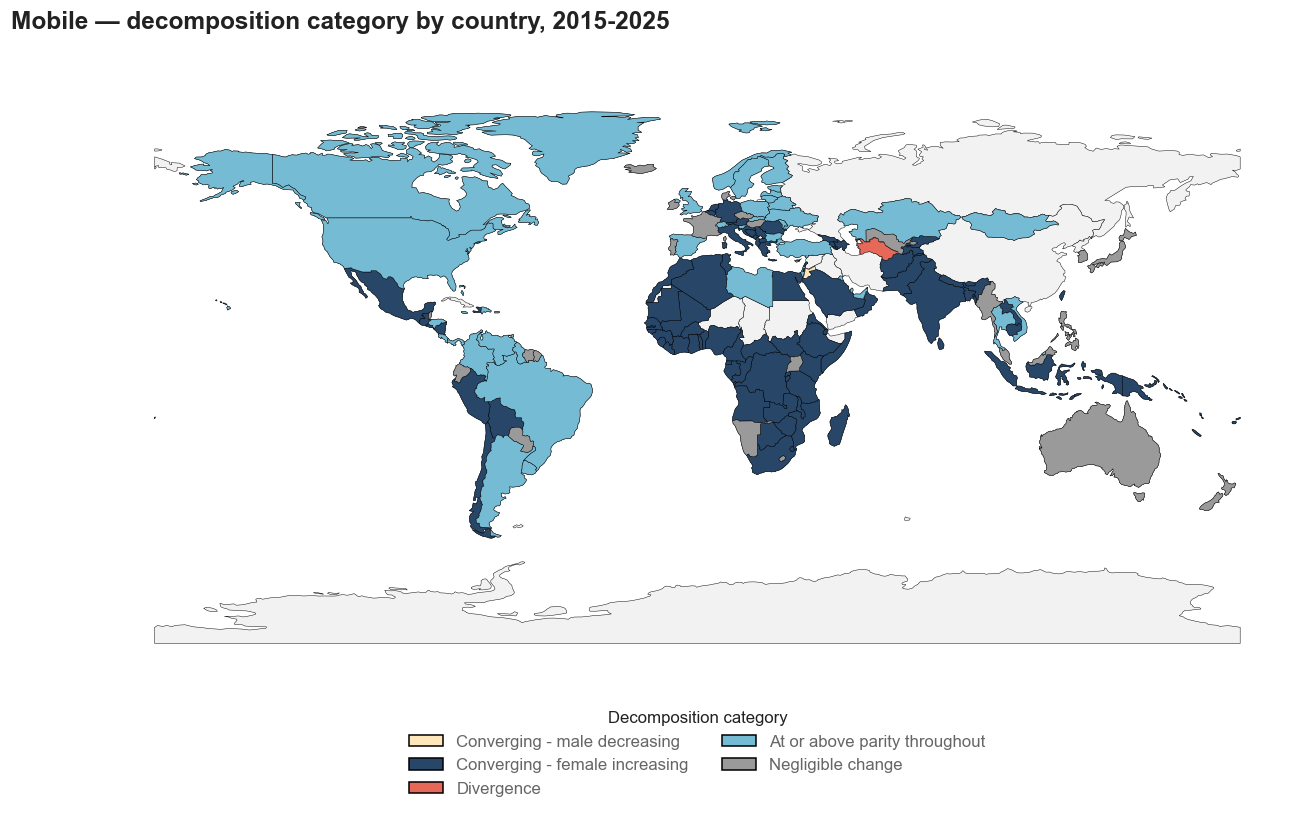

In [11]:
world = utils.load_world()
fig, ax = plt.subplots(figsize=plot.figsize('full'))

block = at(country)
merged = world.merge(block[['gid_0', 'category']], left_on='iso_a3', right_on='gid_0', how='left')

world.plot(ax=ax, color=plot.NODATA, edgecolor=plot.EDGE, linewidth=0.3)
for code_ in sorted(block['category'].dropna().unique()):
    sub = merged[merged['category'] == code_]
    if len(sub):
        sub.plot(ax=ax, edgecolor=plot.EDGE, linewidth=0.3, **cat_style(code_))
ax.axis('off')

fig.legend(handles=legend_handles(block['category'].dropna()), loc='lower center', ncol=2,
           frameon=False, fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.06),
           title='Decomposition category', title_fontsize=STYLE['tick_fs'])
fig.suptitle(f'{INDICATOR.capitalize()} — decomposition category by country, {PRIMARY}',
             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0.10, 1, 0.96])
plot.save_fig(fig, FIGDIR / f'category_map_{INDICATOR}.png')
print(f'  category_map_{INDICATOR}.png  (grey = excluded, no log change defined)')

## Largest parity changes

Twenty largest improvements and deteriorations for the displayed indicator, showing which component drives each.
"Improvement" here refers to **parity** only; the access columns say whether women actually gained.

In [12]:
ext = sel(extremes)
display(ext[ext['rank_type'] == 'largest parity improvement'].head(20).round(4))
ext[ext['rank_type'] == 'largest parity deterioration'].head(20).round(4)

,indicator,gid_0,country,continent,region,delta_log_ggi,female_component,male_component,category_label,parity_direction,female_access_direction,parity_improved_without_access_gain,rank_type
40,mobile,PAK,Pakistan,Asia,South Asia,0.3424,0.5275,-0.1851,Converging - female increasing,improving,expanding,False,largest parity improvement
41,mobile,BEN,Benin,Africa,Sub-Saharan Africa,0.2993,0.5695,-0.2702,Converging - female increasing,improving,expanding,False,largest parity improvement
42,mobile,COD,DR Congo,Africa,Sub-Saharan Africa,0.2882,0.4795,-0.1913,Converging - female increasing,improving,expanding,False,largest parity improvement
43,mobile,SSD,South Sudan,Africa,Sub-Saharan Africa,0.2749,0.5337,-0.2588,Converging - female increasing,improving,expanding,False,largest parity improvement
44,mobile,MWI,Malawi,Africa,Sub-Saharan Africa,0.2643,0.5481,-0.2837,Converging - female increasing,improving,expanding,False,largest parity improvement
45,mobile,BGD,Bangladesh,Asia,South Asia,0.2607,0.5230,-0.2622,Converging - female increasing,improving,expanding,False,largest parity improvement
46,mobile,TGO,Togo,Africa,Sub-Saharan Africa,0.2559,0.4010,-0.1450,Converging - female increasing,improving,expanding,False,largest parity improvement
47,mobile,BFA,Burkina Faso,Africa,Sub-Saharan Africa,0.2558,0.5915,-0.3357,Converging - female increasing,improving,expanding,False,largest parity improvement
48,mobile,MRT,Mauritania,Africa,Sub-Saharan Africa,0.2465,0.4916,-0.2452,Converging - female increasing,improving,expanding,False,largest parity improvement
49,mobile,LBR,Liberia,Africa,Sub-Saharan Africa,0.2290,0.3503,-0.1213,Converging - female increasing,improving,expanding,False,largest parity improvement


,indicator,gid_0,country,continent,region,delta_log_ggi,female_component,male_component,category_label,parity_direction,female_access_direction,parity_improved_without_access_gain,rank_type
60,mobile,KIR,Kiribati,Oceania,East Asia & Pacific,-0.0660,0.1145,-0.1805,Divergence,worsening,expanding,False,largest parity deterioration
61,mobile,TKM,Turkmenistan,Asia,Europe & Central Asia,-0.0419,-0.0288,-0.0131,Divergence,worsening,contracting,False,largest parity deterioration
62,mobile,KOR,South Korea,Asia,East Asia & Pacific,-0.0124,-0.0142,0.0018,Negligible change,stable,contracting,False,largest parity deterioration
63,mobile,MMR,Myanmar,Asia,East Asia & Pacific,-0.0099,-0.3000,0.2901,Negligible change,stable,contracting,False,largest parity deterioration
64,mobile,ABW,Aruba,North America,Latin America & Caribbean,0.0000,0.0367,-0.0367,At or above parity throughout,stable,expanding,False,largest parity deterioration
65,mobile,LIE,Liechtenstein,Europe,Europe & Central Asia,0.0000,0.0000,-0.0000,At or above parity throughout,stable,stable,False,largest parity deterioration
66,mobile,LTU,Lithuania,Europe,Europe & Central Asia,0.0000,0.0987,-0.0987,At or above parity throughout,stable,expanding,False,largest parity deterioration
67,mobile,LUX,Luxembourg,Europe,Europe & Central Asia,0.0000,0.0000,-0.0000,At or above parity throughout,stable,stable,False,largest parity deterioration
68,mobile,LVA,Latvia,Europe,Europe & Central Asia,0.0000,0.0858,-0.0858,At or above parity throughout,stable,expanding,False,largest parity deterioration
69,mobile,MCO,Monaco,Europe,Europe & Central Asia,0.0000,0.0000,-0.0000,At or above parity throughout,stable,stable,False,largest parity deterioration


## Group aggregate decomposition

Grouped by **`GROUPING`** (`continent` by default, or the World Bank `region`). Group levels are the
population-weighted means of country levels, both sexes on the **same** denominator: the country's
total population aged 15–49, the DHS/MICS interview universe (D50). One denominator for both sexes
is what makes the female and male components of an aggregate comparable. Weights are fixed at 2015 —
the UN file stops at 2024 so 2025 has no population of its own, and fixed weights keep the identity
exact by preventing population composition change from entering a decomposition that only claims to
measure adoption change.

,indicator,interval,grouping,group,n_countries,female_level_t0,female_level_t1,male_level_t0,male_level_t1,ggi_t0,ggi_t1,female_component,male_component,delta_log_ggi,parity_direction,female_access_direction
44,mobile,2015-2025,continent,South America,12,0.8151,0.8722,0.8202,0.8723,0.9939,0.9999,0.0676,-0.0616,0.0060,stable,expanding
42,mobile,2015-2025,continent,North America,35,0.8913,0.9646,0.9030,0.9669,0.9870,0.9976,0.0790,-0.0684,0.0107,stable,expanding
41,mobile,2015-2025,continent,Europe,45,0.9053,0.9636,0.9205,0.9639,0.9835,0.9997,0.0624,-0.0460,0.0164,improving,expanding
43,mobile,2015-2025,continent,Oceania,19,0.8432,0.9291,0.8842,0.9528,0.9535,0.9751,0.0971,-0.0747,0.0224,improving,expanding
40,mobile,2015-2025,continent,Asia,45,0.6648,0.8647,0.8414,0.9668,0.7901,0.8943,0.2629,-0.1389,0.1240,improving,expanding
39,mobile,2015-2025,continent,Africa,51,0.5782,0.7420,0.7442,0.8350,0.7769,0.8886,0.2495,-0.1151,0.1343,improving,expanding


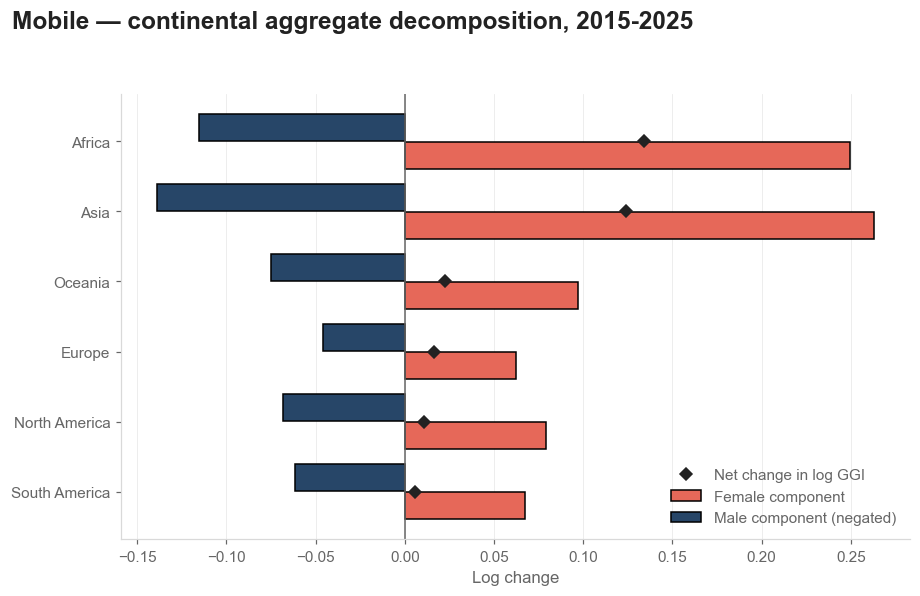

In [13]:
fig, ax = plt.subplots(figsize=plot.figsize('single'))
block = at(group_agg).sort_values('delta_log_ggi')
y = np.arange(len(block))

ax.barh(y - 0.2, block['female_component'], height=0.38, color=PALETTE[0],
        edgecolor=plot.EDGE, label='Female component')
ax.barh(y + 0.2, block['male_component'], height=0.38, color=PALETTE[1],
        edgecolor=plot.EDGE, label='Male component (negated)')
ax.plot(block['delta_log_ggi'], y, 'D', color=INK, markersize=6, label='Net change in log GGI')
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(block['group'])
tidy(ax, xlabel='Log change')
ax.grid(axis='y', visible=False)
ax.grid(axis='x', color=GRID, linewidth=0.5, alpha=0.6)
ax.legend(frameon=False, fontsize=STYLE['annot_fs'], loc='lower right', labelcolor=MUTED)

fig.suptitle(f'{INDICATOR.capitalize()} — {GROUP_ADJ} aggregate decomposition, {PRIMARY}',
             fontsize=STYLE['title_fs'],
             color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.94])
plot.save_fig(fig, FIGDIR / f'group_aggregate_decomposition_{INDICATOR}_{GROUPING}.png')
block.round(4)

## Generated summary

**This is the one section that ignores `INDICATOR`.** (It does not ignore `GROUPING`: the
aggregate paragraphs are written for the grouping on display, and name it.) It writes
`doc/06_coherent_ggi_decomposition_report.md`, a repo artefact referenced from the README, so it covers both
indicators whichever one the figures above are showing. Halving the document to match the display
would be a regression, not a filter.

In [14]:
def summary_text():
    """compose the summary from the tables, keeping parity and access strictly separate"""
    lines = [
        f'Everything below runs on the filtered series: a country-year whose coherent gender gap '
        f'index differs from the directly predicted one by more than {CUT} is withheld for that '
        f'indicator before the decomposition, because a disagreement about the ratio is a '
        f'disagreement about the levels the decomposition attributes change to. The filter costs '
        f"{100 - disc_filter.set_index('indicator').loc['internet', 'kept_pct']:.0f}% of internet "
        f"country-years and {100 - disc_filter.set_index('indicator').loc['mobile', 'kept_pct']:.0f}% "
        f'of mobile ones; because an interval needs a level at both endpoints, the country loss is '
        f'larger still and is stated per indicator below.',

        'Because the coherent gender gap index is a ratio of predicted female to predicted male '
        'adoption, its log change decomposes exactly into a female and a male term. The identity '
        f"holds to {identity['max_abs_residual'].iloc[0]:.0e} across "
        f"{int(identity['n_rows'].iloc[0])} country-periods. This separation matters because a "
        'narrowing gap can reflect women gaining access or men losing it, and only the first is an '
        'expansion of digital access for women. The typology has five categories: the gap narrowed '
        'with female access increasing, it narrowed because male adoption decreased, it widened, the '
        'country was at or above parity throughout, or the change was negligible. A change is '
        f'negligible when the log change in the index is within {ggi_decomposition.TAU} log points '
        'of zero in either direction; the same threshold decides whether female adoption counts as '
        'having expanded.',

        "Population-weighted shares below use each country's total population aged 15-49 in 2015 - "
        'the DHS/MICS interview universe - as a single weight for both sexes, so every weighted '
        'share in this document refers to the same denominator.']

    for ind in params.COHERENT_GGI['indicators']:
        exc = exclusions[(exclusions['indicator'] == ind) & (exclusions['interval'] == PRIMARY)].iloc[0]
        g = cat_global[(cat_global['indicator'] == ind) & (cat_global['interval'] == PRIMARY)]
        g = g.set_index('category')
        converging_f = g.loc[2]
        no_access = g.loc[list(NO_ACCESS_GAIN)]
        diverge = g.loc[3]

        # The exclusion sentence has to name the reason that actually dominates. Since D43 that is
        # the discrepancy filter, not the zero floor.
        #
        # Do NOT add the two zero counts: `n_excluded_zero_female` and `n_excluded_zero_male` are
        # per-endpoint flags on the same rows, so a country with both levels at zero (Niger 2015,
        # the only one) is counted twice and the reasons no longer sum to `n_excluded`. Take the
        # blanked count from `n_excluded_missing`, which is a row count, and leave the rest as
        # zeros — that partitions the exclusions exactly, because `decompose` drops a row for a
        # missing level or a non-positive one and nothing else.
        blanked = int(exc['n_excluded_missing'])
        zero = int(exc['n_excluded']) - blanked
        reason = []
        if blanked:
            reason.append(f"{blanked} because the coherent and the directly predicted index "
                          f"disagree by more than {CUT} at one or both endpoints, so the "
                          'country-year is withheld')
        if zero:
            reason.append(f"{zero} because a predicted level is exactly zero at an endpoint")

        lines.append(
            f"For {ind} over 2015-2025, {int(exc['n_included'])} of "
            f"{int(exc['n_countries_available'])} countries have a defined log change; "
            f"{int(exc['n_excluded'])} are excluded - {'; '.join(reason)}. "
            f"Of those included, {int(converging_f['n_countries'])} "
            f"({converging_f['share_unweighted']:.1%} of countries, "
            f"{converging_f['share_pop_weighted']:.1%} of the population aged 15-49) converged with "
            'female access increasing: the gap narrowed and female adoption rose, proportionally '
            f"faster than male adoption. A further {int(diverge['n_countries'])} "
            f"({diverge['share_unweighted']:.1%}) diverged - the gap widened.")

        at_parity = g.loc[4] if 4 in g.index else None
        if at_parity is not None and int(at_parity['n_countries']):
            lines.append(
                f"A further {int(at_parity['n_countries'])} {ind} countries "
                f"({at_parity['share_unweighted']:.1%} of countries, "
                f"{at_parity['share_pop_weighted']:.1%} of the population aged 15-49) were at or above parity at "
                'both endpoints. They are reported as a standing state rather than as change: there '
                'was no gap against women to close. They are retained in the denominator, because '
                'excluding them would remove countries non-randomly by region and income level.')

        n_no_access = int(no_access['n_countries'].sum())
        if n_no_access:
            names = country[(country['interval'] == PRIMARY) & (country['indicator'] == ind)
                            & country['parity_improved_without_access_gain']]['country'].tolist()
            lines.append(
                f"In {n_no_access} {ind} case(s) - {', '.join(names)} - the gap narrowed without "
                'women gaining access: female adoption was flat or falling, and the gap closed only '
                'because male adoption fell further. These are improvements in parity, not in '
                'digital access, and should not be reported as the latter.')

    # group aggregate: state parity and access separately, and name the grouping — the numbers are
    # not comparable across groupings, so a sentence that does not say which one it used is a trap
    for ind in params.COHERENT_GGI['indicators']:
        r = group_agg[(group_agg['grouping'] == GROUPING)
                      & (group_agg['interval'] == PRIMARY) & (group_agg['indicator'] == ind)]
        improving = r[r['parity_direction'] == 'improving']
        expanding = r[r['female_access_direction'] == 'expanding']
        biggest = r.loc[r['delta_log_ggi'].idxmax()]
        lines.append(
            f"At {GROUP_ADJ} level for {ind}, {len(improving)} of {len(r)} {GROUP_MANY} show improving "
            f"parity and {len(expanding)} of {len(r)} show expanding female access. The largest "
            f"parity gain is {biggest['group']} ({biggest['delta_log_ggi']:+.3f} log points), "
            f"where the female component contributes {biggest['female_component']:+.3f} and the "
            f"male component {biggest['male_component']:+.3f} - that is, female adoption rose "
            f"faster than male adoption, both having risen.")

    lines.append(
        'Two caveats bound the country-level results. The excluded countries are not a random '
        'subset. Most of them are now withheld by the discrepancy filter rather than by the zero '
        'floor of the level model, but the two sets overlap almost completely - the countries whose '
        'predicted female level sits on that floor are also the ones where the coherent and the '
        'directly predicted index disagree most - so the countries that drop out remain among the '
        'most gender-unequal in the sample and the reported distribution understates the tail. And '
        'an epsilon substitution was tested but not adopted, because it changes no existing '
        'estimate and only manufactures a log change where the underlying level is exactly zero.')

    return '\n\n'.join(lines)


text = summary_text()
out = params.DOC / '06_coherent_ggi_decomposition_report.md'
out.write_text('# Decomposition of coherent-GGI change\n\n'
               '<!-- generated by src/analysis_notebooks/06_coherent_ggi_decomposition.ipynb '
               '— do not edit by hand -->\n\n'
               + text + '\n')
print(f'written to {out.relative_to(params.ROOT)}\n')
print(text)

written to doc/06_coherent_ggi_decomposition_report.md

Everything below runs on the filtered series: a country-year whose coherent gender gap index differs from the directly predicted one by more than 0.07 is withheld for that indicator before the decomposition, because a disagreement about the ratio is a disagreement about the levels the decomposition attributes change to. The filter costs 21% of internet country-years and 1% of mobile ones; because an interval needs a level at both endpoints, the country loss is larger still and is stated per indicator below.

Because the coherent gender gap index is a ratio of predicted female to predicted male adoption, its log change decomposes exactly into a female and a male term. The identity holds to 4e-16 across 4752 country-periods. This separation matters because a narrowing gap can reflect women gaining access or men losing it, and only the first is an expansion of digital access for women. The typology has five categories: the gap narrow

## Notes

- `INDICATOR` at the top of the setup cell chooses what is displayed. Figures carry it in their
  filename (`..._{INDICATOR}.png`), so switching and rerunning accumulates both sets rather than
  overwriting one with the other. They write to `outputs/fig/06_coherent_ggi_decomposition/`; every
  table is in `outputs/tables/06_coherent_ggi_decomposition/` under the `ggi_decomposition_` prefix,
  and each still holds **both** indicators — only the display is filtered.
- **`female_vs_male_growth_pair`** is the one figure that ignores `INDICATOR`: internet and mobile
  side by side, same marks and one legend, each panel on its own limits because mobile's log changes
  are about a third the size of internet's. Its aspect is pinned so the diagonal stays at 45° in a
  panel that is no longer a square canvas. The single-indicator version above is unchanged.
- Legends are built from the categories actually present in the panel, so an indicator that occupies
  only part of the typology no longer advertises the empty classes. Internet occupies four of the
  five; mobile occupies all five.
- `GROUPING` chooses how countries are aggregated — `continent` (the default) or the World Bank
  `region`, which mixes geography with income and administrative history. Both are built by
  `src/ggi_decomposition.py` on every run and stacked in `..._category_by_group_*.csv` and
  `..._group_aggregate_*.csv` under a `grouping` column, so switching costs a rerun of the notebook
  and nothing else. The two grouped figures carry it in their filename, and the generated summary
  names it in the text — the aggregate numbers are not comparable across groupings.
- The global and grouped category shares are **one figure of four panels** (`category_shares_*`),
  not two figures: the global strip is the weighted average of the grouped panel above it, and the
  two columns are the two weightings, so the comparison a reader wants is inside one frame.
- **τ = 0.013**, raised from 0.01 (D55). See the codebook section for the case; the ledger figures
  in `doc/STATE.md` are the post-change ones.
- **Parity and access are reported separately throughout.** `parity_direction` and
  `female_access_direction` are distinct columns on every country-period row, and category 1 carries
  `parity_improved_without_access_gain = True`.
- Weights are fixed at the 2015 population aged 15–49, both sexes on one denominator (D50). See the
  group aggregate section for why.